# Task 1b + Task 2: cross-entropy on noisy labels and its training dynamics

ResNet-18 trained with plain cross-entropy on the human noisy labels for the full 60 epochs, same setup as the clean reference. After every epoch the model is evaluated (no augmentation) on:

* the training images whose noisy label is correct, and those whose noisy label is wrong (accuracy against the noisy label, so on the wrong subset it measures how much of the wrong labels the network has fitted);
* the validation set, scored with the noisy labels and with the clean labels.

Clean labels are only used to measure these curves. The early-stopping epoch is chosen from noisy validation accuracy alone.

Outputs: `t1_noisy_ce.csv` (final epoch), `t2_dynamics.csv`, `t2_early_stop.csv`. The per-epoch training-set probabilities are kept in `work/` for Task 3.

Runtime on an A100: about 6 minutes.

In [1]:
# project folder: MyDrive/cv_bootcamp (data/, model.py, check_format.py, results_template.json, code/cvlib.py).
# If it is not there yet, it is unpacked from MyDrive/cv_bootcamp.zip, or from a zip picked in the file dialog.
import sys, zipfile
from pathlib import Path

try:
    from google.colab import drive, files
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/cv_bootcamp")
except ImportError:                      # running outside Colab
    files = None
    ROOT = Path.cwd() / "cv_bootcamp"

if not (ROOT / "data" / "labels.csv").exists():
    zips = [z for z in [ROOT.parent / "cv_bootcamp.zip"] if z.exists()] + list(Path.cwd().glob("cv_bootcamp*.zip"))
    if not zips:
        zips = [Path(name) for name in files.upload()]
    zipfile.ZipFile(zips[0]).extractall(ROOT.parent)
    print("unpacked", zips[0].name, "into", ROOT.parent)

assert (ROOT / "data" / "labels.csv").exists() and (ROOT / "code" / "cvlib.py").exists()
sys.path.insert(0, str(ROOT / "code"))
print("project folder:", ROOT)

Mounted at /content/drive
project folder: /content/drive/MyDrive/cv_bootcamp


In [2]:
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import cvlib as cv

WORK = ROOT / "work"
PRED = ROOT / "predictions"
WORK.mkdir(exist_ok=True)
PRED.mkdir(exist_ok=True)

print("device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu")
data = cv.Data(ROOT)
print("train", len(data.train_idx), " val", len(data.val_idx), " test", len(data.x_test))
print("classes:", data.classes)

device: NVIDIA A100-SXM4-80GB
train 45000  val 5000  test 10000
classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [3]:
lab = data.labels
tr, va = data.train_idx, data.val_idx
noisy, clean = lab["noisy_label"].to_numpy(), lab["clean_label"].to_numpy()

y_tr = noisy[tr]
wrong_tr = noisy[tr] != clean[tr]          # used only to split the training accuracy into two curves
print(f"training images with a wrong label: {wrong_tr.sum()} ({wrong_tr.mean():.4f})")

training images with a wrong label: 18109 (0.4024)


## Training with per-epoch logging

In [4]:
RUN = WORK / "t1_noisy_ce.npz"

if RUN.exists():
    run = dict(np.load(RUN))
    print("loaded", RUN.name)
else:
    rec = cv.Recorder(data, noisy[va])
    train_probs, rows = [], []

    def on_epoch(ep, net):
        info = rec(ep, net)
        p = cv.predict(net, data.x[tr])
        train_probs.append(p.astype(np.float16))
        pred = p.argmax(1)
        pv = rec.val_probs[-1].argmax(1)
        rows.append({
            "epoch": ep,
            "train_acc_correct": float((pred[~wrong_tr] == y_tr[~wrong_tr]).mean()),
            "train_acc_mislabeled": float((pred[wrong_tr] == y_tr[wrong_tr]).mean()),
            "val_acc_noisy": float((pv == noisy[va]).mean()),
            "val_acc_clean": float((pv == clean[va]).mean()),
            # extra: share of wrongly labelled images still predicted as their true class
            "mislabeled_pred_true_class": float((pred[wrong_tr] == clean[tr][wrong_tr]).mean()),
        })
        r = rows[-1]
        return {"fit_wrong": r["train_acc_mislabeled"], "val_noisy": r["val_acc_noisy"], "val_clean": r["val_acc_clean"]}

    net = cv.train(data, tr, y_tr, on_epoch=on_epoch, tag="noisy CE")
    rec.save(RUN, train_probs=np.stack(train_probs), dynamics=pd.DataFrame(rows).to_numpy(),
             dynamics_cols=np.array(list(rows[0].keys())))
    torch.save(net.state_dict(), WORK / "t1_noisy_ce.pt")
    run = dict(np.load(RUN))

dyn = pd.DataFrame(run["dynamics"], columns=[str(c) for c in run["dynamics_cols"]])
dyn["epoch"] = dyn["epoch"].astype(int)
dyn.round(4)

noisy CE epoch  1  loss 2.2291  fit_wrong 0.1530  val_noisy 0.2898  val_clean 0.3698  (18s)
noisy CE epoch  5  loss 1.7639  fit_wrong 0.1442  val_noisy 0.4100  val_clean 0.5426  (36s)
noisy CE epoch 10  loss 1.6226  fit_wrong 0.1392  val_noisy 0.4692  val_clean 0.6330  (58s)
noisy CE epoch 15  loss 1.5257  fit_wrong 0.1367  val_noisy 0.4962  val_clean 0.6994  (80s)
noisy CE epoch 20  loss 1.4814  fit_wrong 0.1257  val_noisy 0.5202  val_clean 0.7270  (102s)
noisy CE epoch 25  loss 1.4457  fit_wrong 0.1368  val_noisy 0.5160  val_clean 0.7248  (124s)
noisy CE epoch 30  loss 1.4081  fit_wrong 0.1401  val_noisy 0.5286  val_clean 0.7644  (146s)
noisy CE epoch 35  loss 1.3651  fit_wrong 0.1672  val_noisy 0.5510  val_clean 0.7790  (168s)
noisy CE epoch 40  loss 1.3050  fit_wrong 0.1895  val_noisy 0.5512  val_clean 0.7758  (190s)
noisy CE epoch 45  loss 1.2041  fit_wrong 0.2413  val_noisy 0.5442  val_clean 0.7724  (212s)
noisy CE epoch 50  loss 1.0290  fit_wrong 0.3710  val_noisy 0.5298  val_cl

,epoch,train_acc_correct,train_acc_mislabeled,val_acc_noisy,val_acc_clean,mislabeled_pred_true_class
0,1,0.3933,0.1530,0.2898,0.3698,0.3266
1,2,0.4296,0.1509,0.3200,0.4098,0.3483
2,3,0.4979,0.1631,0.3594,0.4604,0.4099
3,4,0.5132,0.1450,0.3592,0.4784,0.4361
4,5,0.5933,0.1442,0.4100,0.5426,0.4918
5,6,0.5834,0.1427,0.4032,0.5346,0.4636
6,7,0.6532,0.1321,0.4292,0.5872,0.5270
7,8,0.6166,0.1400,0.4224,0.5596,0.4948
8,9,0.6668,0.1500,0.4472,0.5956,0.5385
9,10,0.6909,0.1392,0.4692,0.6330,0.5546


In [5]:
# submission files: final-epoch test predictions and the per-epoch log in the required column order
cols = ["epoch", "train_acc_correct", "train_acc_mislabeled", "val_acc_noisy", "val_acc_clean"]
dyn[cols].round(6).to_csv(PRED / "t2_dynamics.csv", index=False)
cv.write_preds(PRED / "t1_noisy_ce.csv", run["test_probs"][-1].astype(np.float32))

final = dyn.iloc[-1]
print(f"final epoch {int(final.epoch)}: val acc noisy {final.val_acc_noisy:.4f}, clean {final.val_acc_clean:.4f}, "
      f"fit to wrong labels {final.train_acc_mislabeled:.4f}")
cv.update_results(WORK, task1={"val_acc_noisy_labels__noisy_ce_model": round(float(final.val_acc_noisy), 4)})

final epoch 60: val acc noisy 0.4924, clean 0.6844, fit to wrong labels 0.6808


{'task1': {'noise_rate': 0.4024,
  'val_acc_noisy_labels__clean_ref_model': 0.5918,
  'val_acc_noisy_labels__noisy_ce_model': 0.4924},
 'seed': 42,
 'training_setup': {'optimizer': 'SGD (momentum 0.9, nesterov, weight decay 5e-4)',
  'learning_rate_schedule': 'cosine annealing per step, 0.1 to 0 over 60 epochs, no warmup',
  'batch_size': 128,
  'epochs': 60,
  'augmentation': 'random crop 32x32 with 4-pixel zero padding, random horizontal flip'},
 'extra': {'clean_ref_val_acc_clean': 0.9446}}

## When does memorisation start?

`train_acc_mislabeled` is the share of wrongly labelled training images the network predicts *as their wrong label*. While the network learns general patterns it stays low (most of those images are still predicted as their true class). Once it rises for good, the network is fitting the wrong labels.

Rule used: smooth the curve with a 3-epoch moving average, find its lowest point before the peak, and take the first epoch from which the smoothed curve stays more than 2 points above that floor until the end of training. The clean validation curve is shown alongside as a check.

In [6]:
MEM_START_OVERRIDE = None        # set to an epoch number to replace the automatic rule

m = dyn["train_acc_mislabeled"].to_numpy()
ms = pd.Series(m).rolling(3, center=True, min_periods=1).mean().to_numpy()
low = int(np.argmin(ms[: int(np.argmax(ms)) + 1]))
above = ms > ms[low] + 0.02
mem_start = next((e for e in range(low, len(ms)) if above[e:].all()), low) + 1
if MEM_START_OVERRIDE:
    mem_start = MEM_START_OVERRIDE

clean_peak = int(dyn["val_acc_clean"].idxmax()) + 1
early_stop = int(dyn["val_acc_noisy"].to_numpy().argmax()) + 1      # chosen on noisy val accuracy only

print(f"floor of the wrong-label fit: epoch {low + 1}, {ms[low]:.4f}")
print(f"memorisation starts: epoch {mem_start}  (fit to wrong labels {m[mem_start - 1]:.4f})")
print(f"clean val accuracy peaks at epoch {clean_peak} ({dyn.val_acc_clean.max():.4f}), measured only")
print(f"early-stopping epoch (best noisy val acc): {early_stop}  ({dyn.val_acc_noisy.max():.4f})")

floor of the wrong-label fit: epoch 18, 0.1210
memorisation starts: epoch 31  (fit to wrong labels 0.1281)
clean val accuracy peaks at epoch 43 (0.7844), measured only
early-stopping epoch (best noisy val acc): 38  (0.5560)


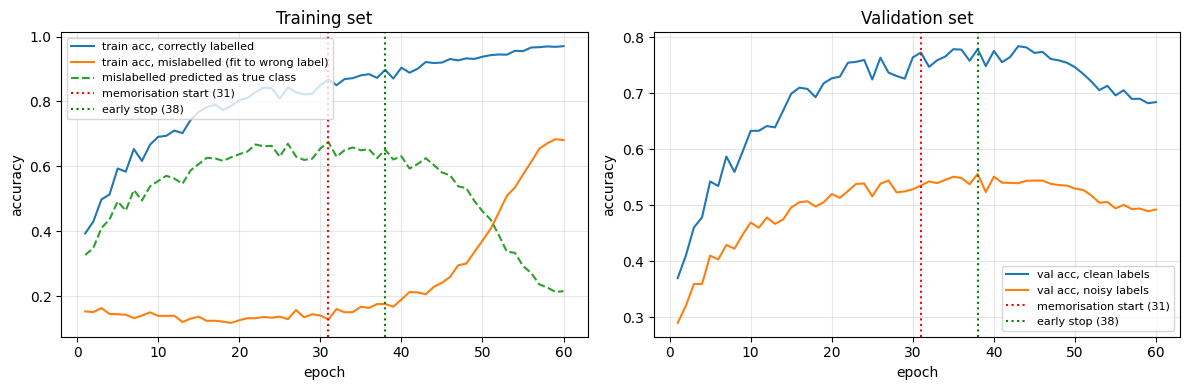

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
e = dyn["epoch"]
ax[0].plot(e, dyn.train_acc_correct, label="train acc, correctly labelled")
ax[0].plot(e, dyn.train_acc_mislabeled, label="train acc, mislabelled (fit to wrong label)")
ax[0].plot(e, dyn.mislabeled_pred_true_class, "--", label="mislabelled predicted as true class")
ax[1].plot(e, dyn.val_acc_clean, label="val acc, clean labels")
ax[1].plot(e, dyn.val_acc_noisy, label="val acc, noisy labels")
for a in ax:
    a.axvline(mem_start, color="red", ls=":", label=f"memorisation start ({mem_start})")
    a.axvline(early_stop, color="green", ls=":", label=f"early stop ({early_stop})")
    a.set_xlabel("epoch"); a.set_ylabel("accuracy"); a.grid(alpha=0.3); a.legend(fontsize=8)
ax[0].set_title("Training set"); ax[1].set_title("Validation set")
fig.tight_layout(); fig.savefig(WORK / "t2_dynamics.png", dpi=150); plt.show()

## Early-stopped predictions

In [8]:
es = dyn.iloc[early_stop - 1]
cv.write_preds(PRED / "t2_early_stop.csv", run["test_probs"][early_stop - 1].astype(np.float32))
print(f"epoch {early_stop}: val acc noisy {es.val_acc_noisy:.4f} (final {final.val_acc_noisy:.4f}), "
      f"clean {es.val_acc_clean:.4f} (final {final.val_acc_clean:.4f})")
print(f"fit to wrong labels at the early stop: {es.train_acc_mislabeled:.4f}, at the end: {final.train_acc_mislabeled:.4f}")

cv.update_results(WORK,
    task2={"memorization_start_epoch": mem_start, "early_stop_epoch": early_stop,
           "val_acc_noisy_labels_at_early_stop": round(float(es.val_acc_noisy), 4)},
    extra={"noisy_ce_val_acc_clean_final": round(float(final.val_acc_clean), 4),
           "noisy_ce_val_acc_clean_early_stop": round(float(es.val_acc_clean), 4),
           "clean_val_peak_epoch": clean_peak})
print(json.dumps(cv.load_results(WORK), indent=2))

epoch 38: val acc noisy 0.5560 (final 0.4924), clean 0.7790 (final 0.6844)
fit to wrong labels at the early stop: 0.1756, at the end: 0.6808
{
  "task1": {
    "noise_rate": 0.4024,
    "val_acc_noisy_labels__clean_ref_model": 0.5918,
    "val_acc_noisy_labels__noisy_ce_model": 0.4924
  },
  "seed": 42,
  "training_setup": {
    "optimizer": "SGD (momentum 0.9, nesterov, weight decay 5e-4)",
    "learning_rate_schedule": "cosine annealing per step, 0.1 to 0 over 60 epochs, no warmup",
    "batch_size": 128,
    "epochs": 60,
    "augmentation": "random crop 32x32 with 4-pixel zero padding, random horizontal flip"
  },
  "extra": {
    "clean_ref_val_acc_clean": 0.9446,
    "noisy_ce_val_acc_clean_final": 0.6844,
    "noisy_ce_val_acc_clean_early_stop": 0.779,
    "clean_val_peak_epoch": 43
  },
  "task2": {
    "memorization_start_epoch": 31,
    "early_stop_epoch": 38,
    "val_acc_noisy_labels_at_early_stop": 0.556
  }
}
